In [10]:
%pip install --upgrade mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [14]:
con = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="commonwealth_games_2026"
)


In [13]:
import mysql.connector
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


C:\Users\HP\AppData\Local\Temp\ipykernel_9692\4158378591.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q1 = pd.read_sql(query_1, con)


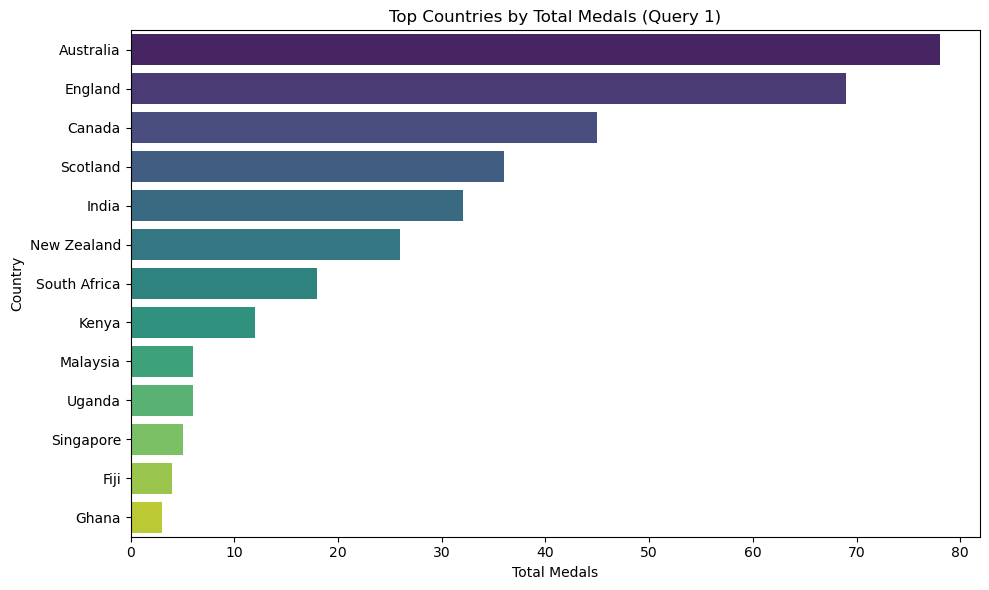

In [4]:


con = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="commonwealth_games_2026"
)

query_1 = """
SELECT 
    c.country_name,
    SUM(m.gold) AS total_gold,
    SUM(m.silver) AS total_silver,
    SUM(m.bronze) AS total_bronze,
    (SUM(m.gold) + SUM(m.silver) + SUM(m.bronze)) AS total_medals
FROM medal_standings m
JOIN countries c ON m.country_id = c.country_id
GROUP BY c.country_id, c.country_name
ORDER BY total_medals DESC;
"""

df_q1 = pd.read_sql(query_1, con)
con.close()

if not df_q1.empty:
    fig, ax = plt.subplots(figsize=(10, 6))

    sns.barplot(
        ax=ax,
        x="total_medals",
        y="country_name",
        data=df_q1,
        palette="viridis",
        hue="country_name",
        legend=False
    )

    ax.set_title("Top Countries by Total Medals (Query 1)")
    ax.set_xlabel("Total Medals")
    ax.set_ylabel("Country")

    plt.tight_layout()
    plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\2263207701.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q2 = pd.read_sql(query_2, con)


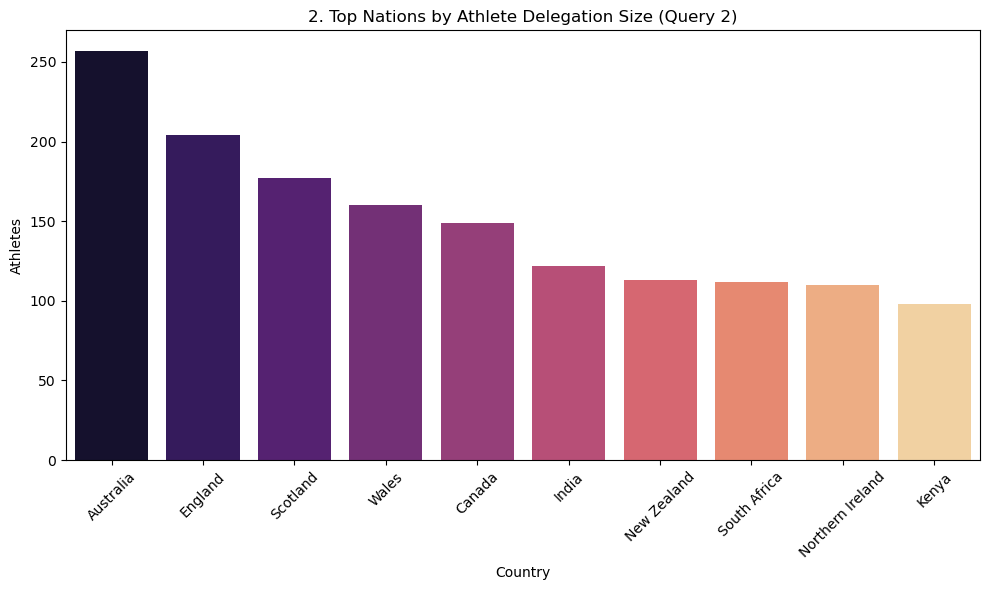

In [8]:



query_2 = """
SELECT c.country_name, c.athlete_count 
FROM countries c 
ORDER BY c.athlete_count DESC;
"""

# Fetch data safely using pandas directly
df_q2 = pd.read_sql(query_2, con)
con.close()

# Plotting the top 10 countries by athlete count
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    ax=ax,
    x="country_name",
    y="athlete_count",
    data=df_q2.head(10),
    palette="magma",
    hue="country_name",
    dodge=False,
)
ax.set_title("2. Top Nations by Athlete Delegation Size (Query 2)")
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Country")
ax.set_ylabel("Athletes")

if ax.legend_:
  ax.legend_.remove()

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\4006026483.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q3 = pd.read_sql(query_3, con)


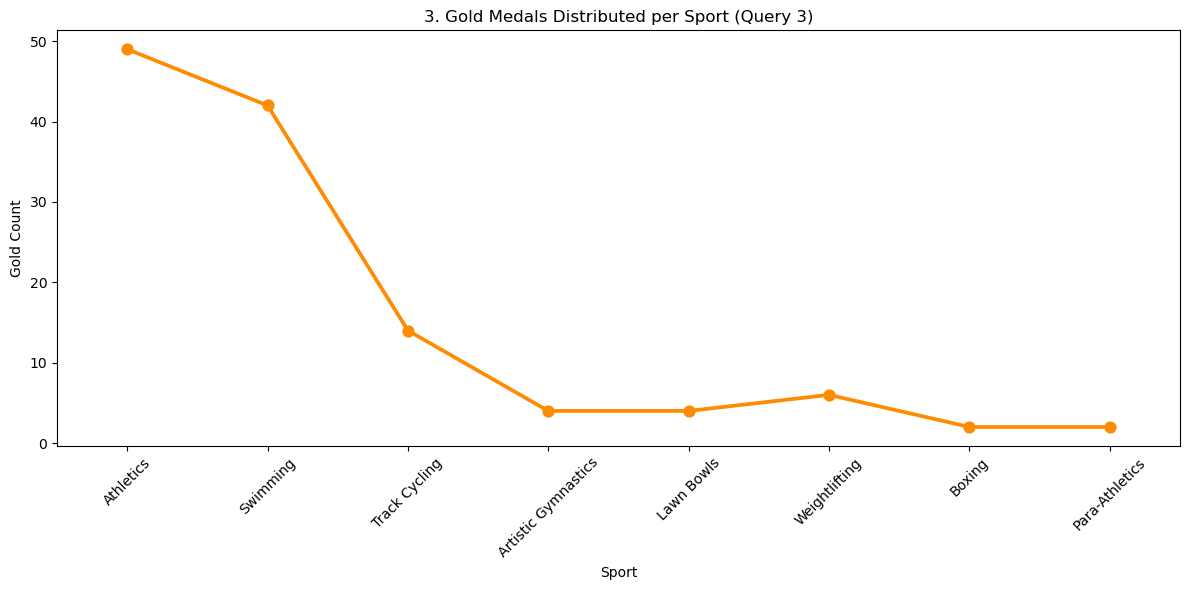

In [15]:


query_3 = """
SELECT e.sport_name, SUM(m.gold) AS gold_medals 
FROM events e 
JOIN medal_standings m ON e.event_id = m.event_id 
GROUP BY e.sport_name;
"""

df_q3 = pd.read_sql(query_3, con)

fig, ax = plt.subplots(figsize=(12, 6))
sns.pointplot(
    ax=ax,
    x="sport_name",
    y="gold_medals",
    data=df_q3,
    color="darkorange",
    markers="o",
    linestyles="-",
)
ax.set_title("3. Gold Medals Distributed per Sport (Query 3)")
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Sport")
ax.set_ylabel("Gold Count")

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\1285721187.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q4 = pd.read_sql(query_4, con)


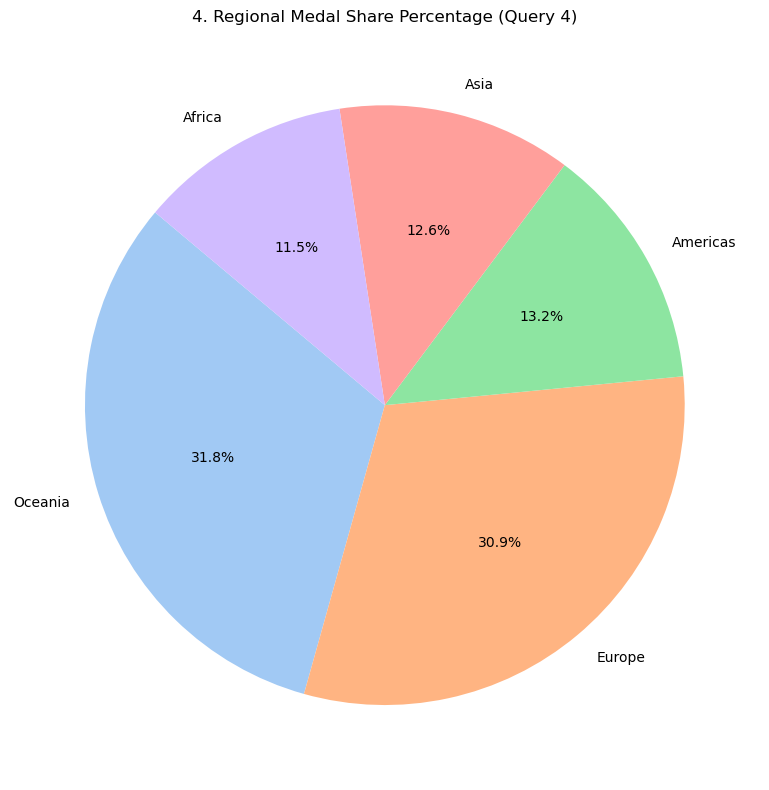

In [16]:
query_4 = """
SELECT c.region, SUM(m.gold + m.silver + m.bronze) as regional_medals 
FROM countries c 
JOIN medal_standings m ON c.country_id = m.country_id 
GROUP BY c.region;
"""

df_q4 = pd.read_sql(query_4, con)

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    df_q4["regional_medals"],
    labels=df_q4["region"],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel"),
)
ax.set_title("4. Regional Medal Share Percentage (Query 4)")

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\2262669396.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q5 = pd.read_sql(query_5, con)


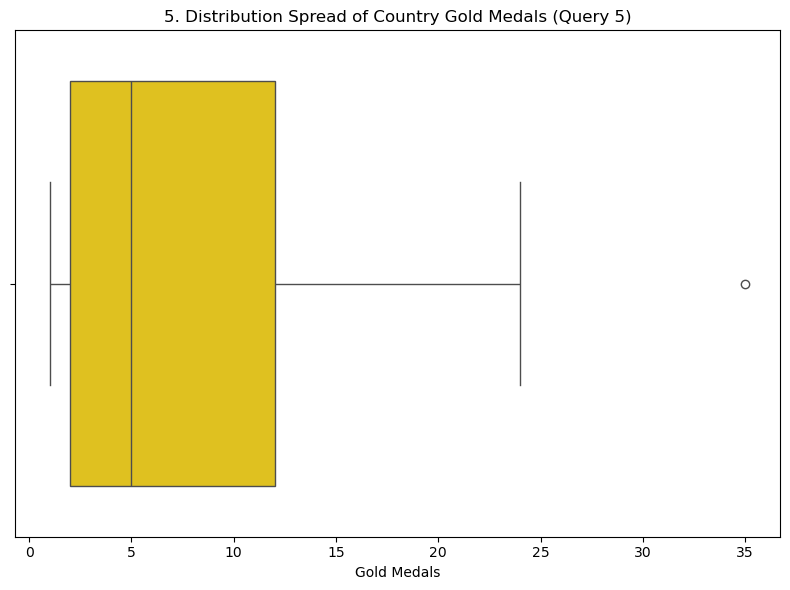

In [17]:
query_5 = """
SELECT c.country_name, SUM(m.gold) as total_gold 
FROM countries c 
JOIN medal_standings m ON c.country_id = m.country_id 
GROUP BY c.country_name 
ORDER BY total_gold DESC;
"""

df_q5 = pd.read_sql(query_5, con)

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(ax=ax, x=df_q5["total_gold"], color="gold", showcaps=True)
ax.set_title("5. Distribution Spread of Country Gold Medals (Query 5)")
ax.set_xlabel("Gold Medals")

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\3466347249.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q6 = pd.read_sql(query_6, con)


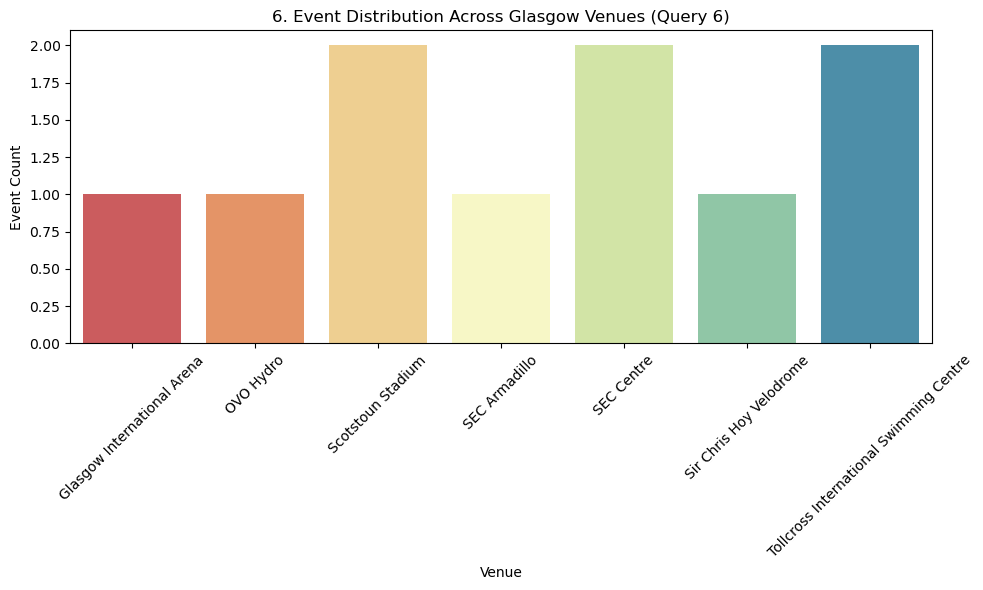

In [18]:
query_6 = """
SELECT e.venue, COUNT(DISTINCT e.event_id) as event_count 
FROM events e 
GROUP BY e.venue;
"""

df_q6 = pd.read_sql(query_6, con)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    ax=ax,
    x="venue",
    y="event_count",
    data=df_q6,
    palette="Spectral",
    hue="venue",
    legend=False,
)
ax.set_title("6. Event Distribution Across Glasgow Venues (Query 6)")
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Venue")
ax.set_ylabel("Event Count")

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\2614983164.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q7 = pd.read_sql(query_7, con)


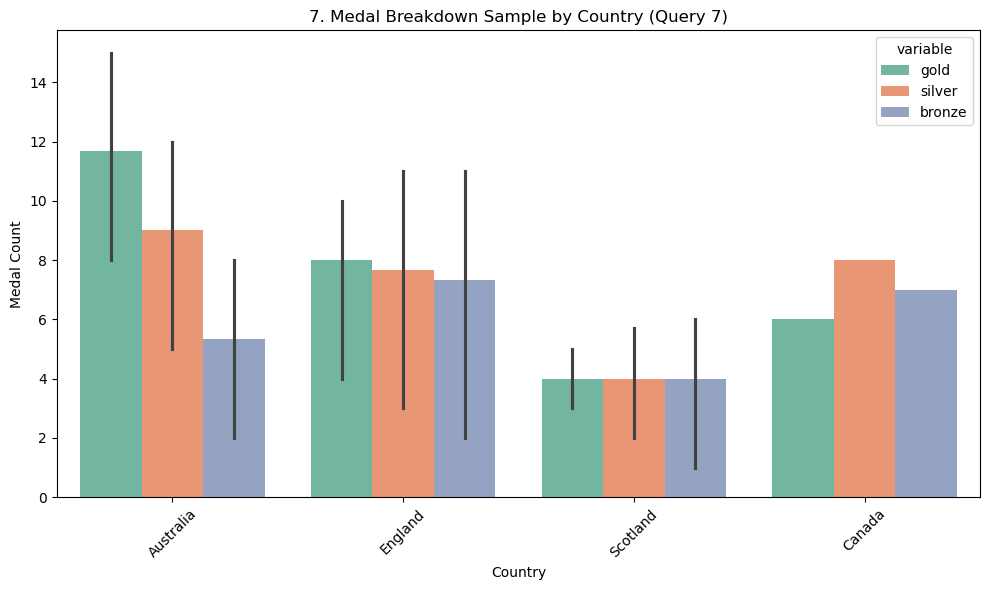

In [21]:

query_7 = """
SELECT c.country_name, m.gold, m.silver, m.bronze 
FROM medal_standings m 
JOIN countries c ON m.country_id = c.country_id 
LIMIT 10;
"""

df_q7 = pd.read_sql(query_7, con)

df_q7_melted = pd.melt(
    df_q7, 
    id_vars=["country_name"], 
    value_vars=["gold", "silver", "bronze"],
    var_name="variable", 
    value_name="value"
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    ax=ax,
    x="country_name",
    y="value",
    hue="variable",
    data=df_q7_melted,
    palette="Set2",
)
ax.set_title("7. Medal Breakdown Sample by Country (Query 7)")
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Country")
ax.set_ylabel("Medal Count")

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\3161814596.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_q8 = pd.read_sql(query_8, con)


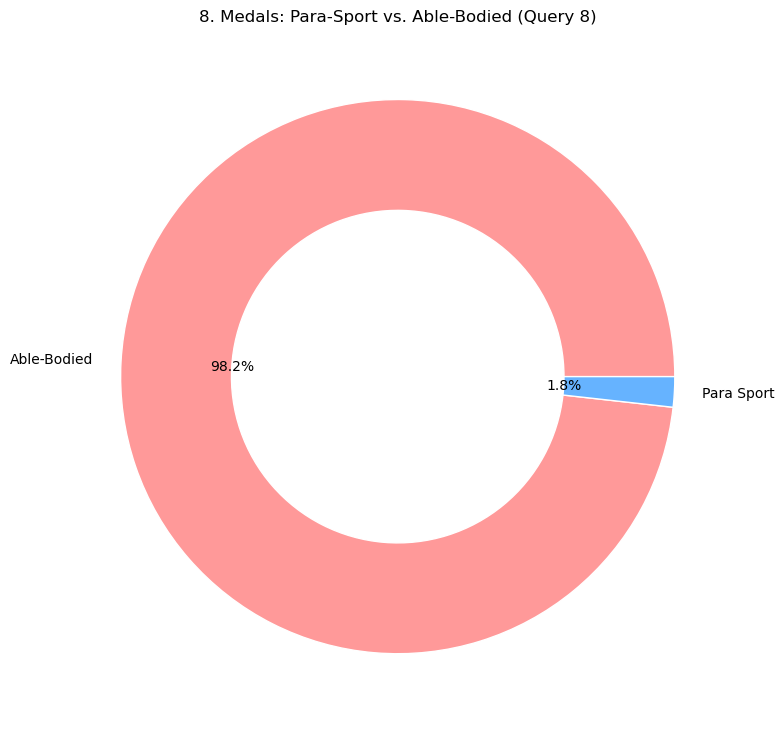

In [22]:
query_8 = """
SELECT CASE WHEN e.is_para_sport = 1 THEN 'Para Sport' ELSE 'Able-Bodied' END as sport_type, 
       SUM(m.gold + m.silver + m.bronze) as total_medals 
FROM events e 
JOIN medal_standings m ON e.event_id = m.event_id 
GROUP BY sport_type;
"""

df_q8 = pd.read_sql(query_8, con)

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    df_q8["total_medals"],
    labels=df_q8["sport_type"],
    autopct="%1.1f%%",
    colors=["#ff9999", "#66b3ff"],
    wedgeprops=dict(width=0.4, edgecolor="w"),
)
ax.set_title("8. Medals: Para-Sport vs. Able-Bodied (Query 8)")

plt.tight_layout()
plt.show()

In [28]:


query_9 = """
SELECT c.country_name, (SUM(m.gold + m.silver + m.bronze) * 1.0 / c.athlete_count) as efficiency 
FROM countries c 
JOIN medal_standings m ON c.country_id = m.country_id 
GROUP BY c.country_id, c.country_name, c.athlete_count 
HAVING c.athlete_count > 0 
ORDER BY efficiency DESC;
"""

cursor = con.cursor(dictionary=True)
cursor.execute(query_9)
df_q9 = pd.DataFrame(cursor.fetchall())
cursor.close()

if df_q9.empty:
    print("No Data")
else:
    df_q9["efficiency"] = pd.to_numeric(df_q9["efficiency"], errors="coerce").fillna(0)

    fig = px.scatter_geo(
        df_q9,
        locations="country_name",
        locationmode="country names",
        size="efficiency",                  
        color="efficiency",                  
        color_continuous_scale="Plasma",
        hover_name="country_name",
        title="9. Country Medal Efficiency Index (Global Bubble Map)"
    )

    fig.update_layout(
        title_font_size=16,
        geo=dict(
            showframe=False,
            showcoastlines=True,
            projection_type="natural earth",
            landcolor="#f0f0f0",
            oceancolor="#f9f9f9",
            showocean=True
        )
    )

    fig.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9692\2513742842.py:20: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



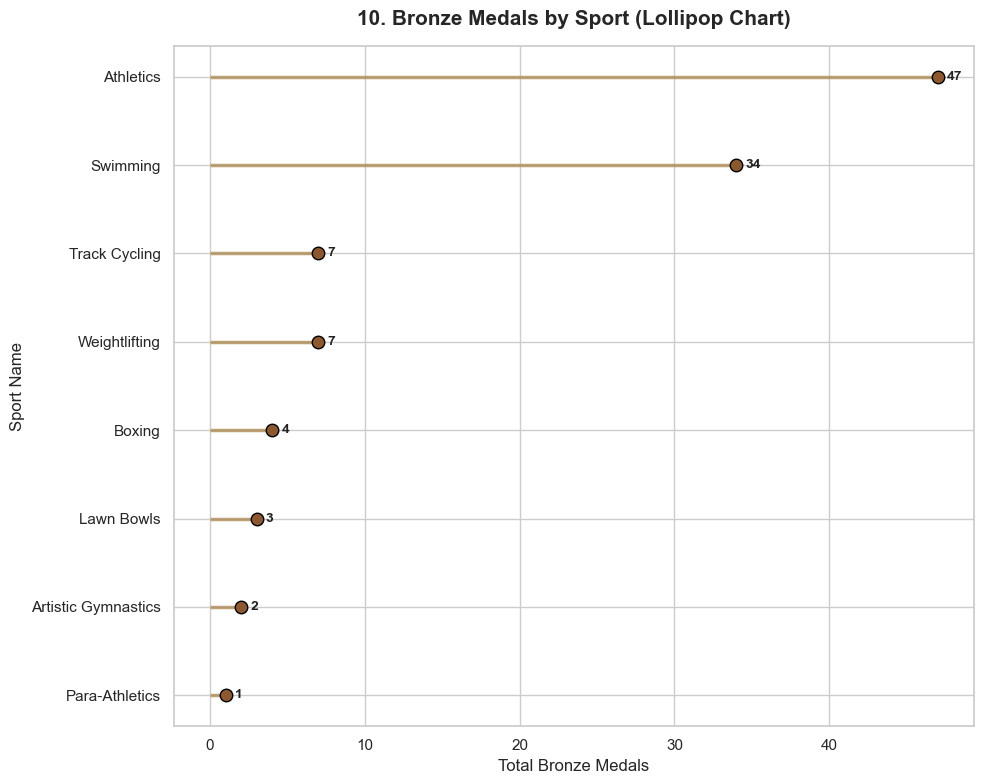

In [30]:



sns.set_theme(style="whitegrid")

query_10 = """
SELECT e.sport_name, SUM(m.bronze) as total_bronze 
FROM events e 
JOIN medal_standings m ON e.event_id = m.event_id 
GROUP BY e.sport_name
ORDER BY total_bronze DESC;
"""

cursor = con.cursor(dictionary=True)
cursor.execute(query_10)
df_q10 = pd.DataFrame(cursor.fetchall())
cursor.close()

if df_q10.empty:
    print("Warning: Query returned no data. Please check table joins or foreign key relationships.")
else:
    
    df_q10["total_bronze"] = pd.to_numeric(df_q10["total_bronze"], errors="coerce").fillna(0)

    fig, ax = plt.subplots(figsize=(10, 8))

    
    ax.hlines(
        y=df_q10["sport_name"], 
        xmin=0, 
        xmax=df_q10["total_bronze"], 
        color="#b08d57",          
        linewidth=2.5, 
        alpha=0.8
    )

  
    ax.plot(
        df_q10["total_bronze"], 
        df_q10["sport_name"], 
        "o",                      
        color="#8c5830",          
        markersize=9, 
        markeredgecolor="black", 
        markeredgewidth=1
    )

    for _, row in df_q10.iterrows():
        ax.text(
            row["total_bronze"] + 0.6,    
            row["sport_name"],            
            str(int(row["total_bronze"])),
            va="center",                  
            ha="left",                    
            fontsize=10, 
            weight="bold",
            color="#222222"
        )

    #
    ax.set_title("10. Bronze Medals by Sport (Lollipop Chart)", fontsize=15, pad=15, weight="bold")
    ax.set_xlabel("Total Bronze Medals", fontsize=12)
    ax.set_ylabel("Sport Name", fontsize=12)

    
    ax.invert_yaxis()

    plt.tight_layout()
    plt.show()

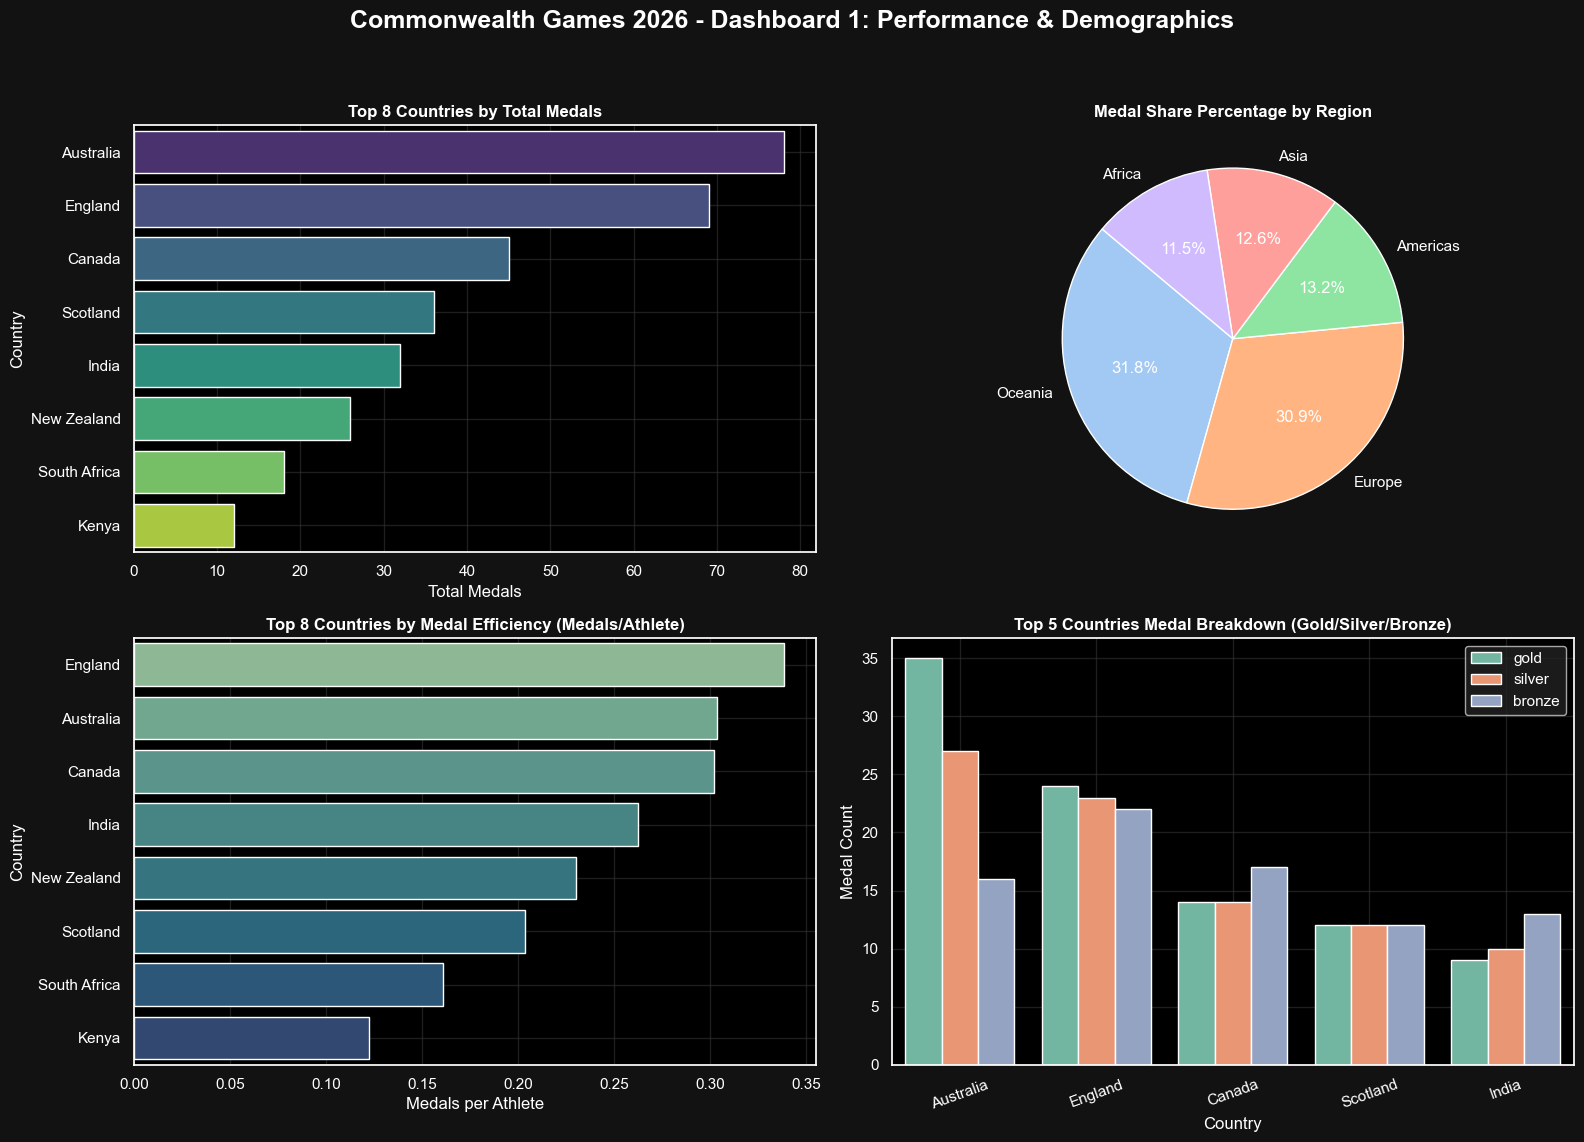

In [37]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sqlalchemy import create_engine


plt.style.use("dark_background")
plt.rcParams.update({"figure.autolayout": True})

df_d1_q1 = pd.read_sql(
    """
    SELECT c.country_name, SUM(m.gold + m.silver + m.bronze) AS total_medals 
    FROM countries c JOIN medal_standings m ON c.country_id = m.country_id 
    GROUP BY c.country_name ORDER BY total_medals DESC LIMIT 8;
""",
    engine,
)

df_d1_q2 = pd.read_sql(
    """
    SELECT c.region, SUM(m.gold + m.silver + m.bronze) AS regional_medals 
    FROM countries c JOIN medal_standings m ON c.country_id = m.country_id 
    GROUP BY c.region;
""",
    engine,
)

df_d1_q3 = pd.read_sql(
    """
    SELECT c.country_name, (SUM(m.gold + m.silver + m.bronze) / c.athlete_count) AS medals_per_athlete 
    FROM countries c JOIN medal_standings m ON c.country_id = m.country_id 
    WHERE c.athlete_count > 0 
    GROUP BY c.country_name, c.athlete_count 
    ORDER BY medals_per_athlete DESC LIMIT 8;
""",
    engine,
)

df_d1_q4 = pd.read_sql(
    """
    SELECT c.country_name, SUM(m.gold) as gold, SUM(m.silver) as silver, SUM(m.bronze) as bronze 
    FROM countries c JOIN medal_standings m ON c.country_id = m.country_id 
    GROUP BY c.country_name ORDER BY (SUM(m.gold)+SUM(m.silver)+SUM(m.bronze)) DESC LIMIT 5;
""",
    engine,
)


df_d1_q4_melted = pd.melt(
    df_d1_q4,
    id_vars=["country_name"],
    value_vars=["gold", "silver", "bronze"],
    var_name="variable",
    value_name="value"
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor("#121212")

fig.suptitle(
    "Commonwealth Games 2026 - Dashboard 1: Performance & Demographics",
    fontsize=18,
    weight="bold",
    color="white",
)

# Chart 1. Top 8 Countries by Total Medals
sns.barplot(
    ax=axes[0, 0],
    x="total_medals",
    y="country_name",
    data=df_d1_q1,
    palette="viridis",
    hue="country_name",
    legend=False,
)
axes[0, 0].set_title(
    "Top 8 Countries by Total Medals", fontsize=12, weight="bold", color="white"
)
axes[0, 0].set_xlabel("Total Medals", color="white")
axes[0, 0].set_ylabel("Country", color="white")
axes[0, 0].tick_params(colors="white")
axes[0, 0].grid(True, color="#333333", alpha=0.6)

# Chart 2: Regional Medal Share (Pie Chart)
axes[0, 1].pie(
    df_d1_q2["regional_medals"],
    labels=df_d1_q2["region"],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel"),
    textprops=dict(color="white"),
)
axes[0, 1].set_title(
    "Medal Share Percentage by Region", fontsize=12, weight="bold", color="white"
)

# Chart 3: Top 8 Countries by Medal Efficiency (Medals per Athlete)
sns.barplot(
    ax=axes[1, 0],
    x="medals_per_athlete",
    y="country_name",
    data=df_d1_q3,
    palette="crest",
    hue="country_name",
    legend=False,
)
axes[1, 0].set_title(
    "Top 8 Countries by Medal Efficiency (Medals/Athlete)",
    fontsize=12,
    weight="bold",
    color="white",
)
axes[1, 0].set_xlabel("Medals per Athlete", color="white")
axes[1, 0].set_ylabel("Country", color="white")
axes[1, 0].tick_params(colors="white")
axes[1, 0].grid(True, color="#333333", alpha=0.6)

# Chart 4: Grouped Medal Breakdown (Gold, Silver, Bronze)
sns.barplot(
    ax=axes[1, 1],
    x="country_name",
    y="value",
    hue="variable",
    data=df_d1_q4_melted,
    palette="Set2",
)
axes[1, 1].set_title(
    "Top 5 Countries Medal Breakdown (Gold/Silver/Bronze)",
    fontsize=12,
    weight="bold",
    color="white",
)
axes[1, 1].tick_params(axis="x", rotation=20, colors="white")
axes[1, 1].tick_params(axis="y", colors="white")
axes[1, 1].set_xlabel("Country", color="white")
axes[1, 1].set_ylabel("Medal Count", color="white")
axes[1, 1].grid(True, color="#333333", alpha=0.6)


legend = axes[1, 1].legend()
if legend:
    plt.setp(legend.get_texts(), color="white")
    legend.get_frame().set_facecolor("#222222")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

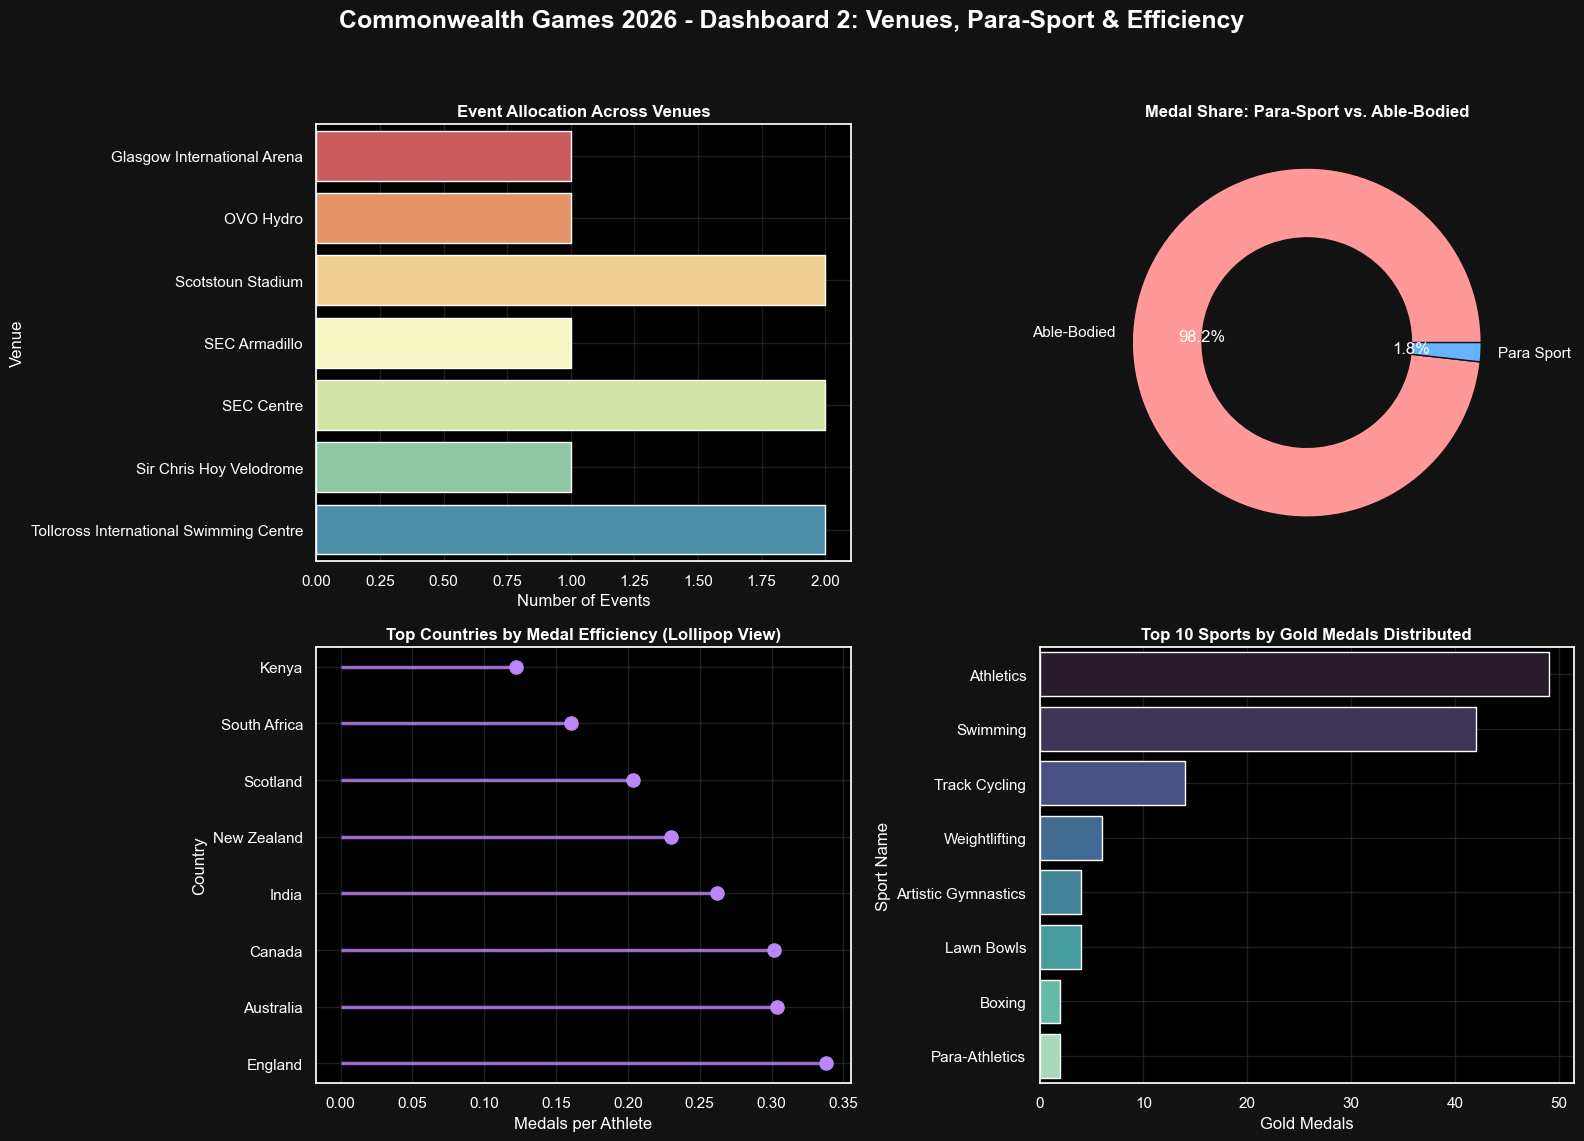

In [38]:
#DashBoard 2


plt.style.use("dark_background")
plt.rcParams.update({"figure.autolayout": True})


df_d2_q1 = pd.read_sql(
    """
    SELECT e.venue, COUNT(DISTINCT e.event_id) as event_count 
    FROM events e GROUP BY e.venue;
""",
    engine,
)

df_d2_q2 = pd.read_sql(
    """
    SELECT 
        CASE 
            WHEN LOWER(e.sport_name) LIKE '%para%' THEN 'Para Sport' 
            ELSE 'Able-Bodied' 
        END as sport_type, 
        SUM(m.gold + m.silver + m.bronze) as total_medals 
    FROM events e 
    JOIN medal_standings m ON e.event_id = m.event_id 
    GROUP BY sport_type;
""",
    engine,
)

df_d2_q3 = pd.read_sql(
    """
    SELECT c.country_name, (SUM(m.gold + m.silver + m.bronze) * 1.0 / c.athlete_count) as efficiency 
    FROM countries c JOIN medal_standings m ON c.country_id = m.country_id 
    GROUP BY c.country_id, c.country_name, c.athlete_count 
    HAVING c.athlete_count > 0 ORDER BY efficiency DESC LIMIT 8;
""",
    engine,
)

df_d2_q4 = pd.read_sql(
    """
    SELECT e.sport_name, SUM(m.gold) as gold_medals 
    FROM events e JOIN medal_standings m ON e.event_id = m.event_id 
    GROUP BY e.sport_name 
    ORDER BY gold_medals DESC LIMIT 10;
""",
    engine,
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor("#121212")

fig.suptitle(
    "Commonwealth Games 2026 - Dashboard 2: Venues, Para-Sport & Efficiency",
    fontsize=18,
    weight="bold",
    color="white",
)

# Chart 1: Events across venues (Horizontal Bar Chart)
sns.barplot(
    ax=axes[0, 0],
    x="event_count",
    y="venue",
    data=df_d2_q1,
    palette="Spectral",
    hue="venue",
    legend=False,
)
axes[0, 0].set_title(
    "Event Allocation Across Venues", fontsize=12, weight="bold", color="white"
)
axes[0, 0].set_xlabel("Number of Events", color="white")
axes[0, 0].set_ylabel("Venue", color="white")
axes[0, 0].tick_params(colors="white")
axes[0, 0].grid(True, color="#333333", alpha=0.6)

# Chart 2: Para vs Able-Bodied (Donut Chart)
axes[0, 1].pie(
    df_d2_q2["total_medals"],
    labels=df_d2_q2["sport_type"],
    autopct="%1.1f%%",
    colors=["#ff9999", "#66b3ff"],
    wedgeprops=dict(width=0.4, edgecolor="#121212"),
    textprops=dict(color="white"),
)
axes[0, 1].set_title(
    "Medal Share: Para-Sport vs. Able-Bodied",
    fontsize=12,
    weight="bold",
    color="white",
)

# Chart 3: Medal Efficiency Ratio (Modern Lollipop Chart)
axes[1, 0].hlines(
    y=df_d2_q3["country_name"],
    xmin=0,
    xmax=df_d2_q3["efficiency"],
    color="#bb86fc",
    alpha=0.8,
    linewidth=2.5,
)
axes[1, 0].scatter(
    df_d2_q3["efficiency"],
    df_d2_q3["country_name"],
    color="#bb86fc",
    s=90,
    zorder=3,
)
axes[1, 0].set_title(
    "Top Countries by Medal Efficiency (Lollipop View)",
    fontsize=12,
    weight="bold",
    color="white",
)
axes[1, 0].set_xlabel("Medals per Athlete", color="white")
axes[1, 0].set_ylabel("Country", color="white")
axes[1, 0].tick_params(colors="white")
axes[1, 0].grid(True, color="#333333", alpha=0.6)

# Chart 4: Top 10 Sports by Gold Medals (Horizontal Ranking Bar Chart)
sns.barplot(
    ax=axes[1, 1],
    x="gold_medals",
    y="sport_name",
    data=df_d2_q4,
    palette="mako",
    hue="sport_name",
    legend=False,
)
axes[1, 1].set_title(
    "Top 10 Sports by Gold Medals Distributed",
    fontsize=12,
    weight="bold",
    color="white",
)
axes[1, 1].set_xlabel("Gold Medals", color="white")
axes[1, 1].set_ylabel("Sport Name", color="white")
axes[1, 1].tick_params(colors="white")
axes[1, 1].grid(True, color="#333333", alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()